### Célula 0 — Setup e conexão

In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from databricks import sql

load_dotenv()

# Parâmetro do pipeline — "store" ou "warehouse".
# Trocar aqui e reexecutar o notebook do início é o que gera a segunda passagem (Centro de Distribuição),
# sem duplicar nenhuma lógica de query.
LOCATION_TYPE = "warehouse"

connection = sql.connect(
    server_hostname=os.environ["DATABRICKS_HOST"],
    http_path=os.environ["DATABRICKS_HTTP_PATH"],
    access_token=os.environ["DATABRICKS_TOKEN"],
    catalog=os.environ.get("DATABRICKS_CATALOG", "dev"),
    schema="gold",
)

def run_query(query: str) -> pd.DataFrame:
    """Executa uma query no SQL Warehouse e retorna um DataFrame pandas."""
    with connection.cursor() as cursor:
        cursor.execute(query)
        if cursor.description is None:
            return pd.DataFrame()
        rows = cursor.fetchall()
        columns = [desc[0] for desc in cursor.description]
        return pd.DataFrame(rows, columns=columns)

### Célula 1 — Base de análise (REFATORADA: lê da mart oficial, sem recalcular janela na mão)

**O que mudou e por quê:** `eda_base` agora lê de `fct_demanda_mensal_produto_local` em vez de reagregar `fct_orders` — corrige o bug de nunca ver a quarentena de dados futuros (ela só existe dentro do modelo dbt da mart). E `eda_historico` deixou de recalcular `meses_com_venda`/`meses_de_vida`/`pct_cobertura` via uma CTE de janela — a mart **já calcula essas três colunas**, com a quarentena já aplicada, então é só ler os valores prontos. Menos código, e elimina a chance de a lógica do notebook divergir da lógica da mart no futuro.

In [10]:
run_query(f"""
CREATE OR REPLACE TEMP VIEW eda_base AS
SELECT
    product_variant_id,
    category_name,
    location_id,
    ano,
    mes,
    mes_ref,
    quantidade_mes,
    valor_liquido_mes
FROM fct_demanda_mensal_produto_local
WHERE location_type = '{LOCATION_TYPE}'
""")

run_query(f"""
CREATE OR REPLACE TEMP VIEW eda_historico AS
SELECT DISTINCT
    product_variant_id,
    location_id,
    meses_com_venda,
    meses_de_vida,
    pct_cobertura
FROM fct_demanda_mensal_produto_local
WHERE location_type = '{LOCATION_TYPE}'
""")

df_hist = run_query("SELECT * FROM eda_historico")

### Célula 2 — Distribuição real de meses_com_venda e pct_cobertura

In [11]:
print(df_hist['meses_com_venda'].describe(percentiles=[.1, .5, .75, .9, .95, .99]))
print(df_hist['pct_cobertura'].describe(percentiles=[.1, .5, .75, .9, .95, .99]))

count    3027.000000
mean       19.246118
std         3.704271
min         8.000000
10%        15.000000
50%        19.000000
75%        22.000000
90%        24.000000
95%        25.000000
99%        28.000000
max        33.000000
Name: meses_com_venda, dtype: float64
count    3027.000000
mean        0.264541
std         0.048576
min         0.121000
10%         0.203000
50%         0.263000
75%         0.297000
90%         0.328000
95%         0.347000
99%         0.380480
max         0.451000
Name: pct_cobertura, dtype: float64


### Célula 3 — Grade de candidatos a limiar, derivada dos percentis reais

⚠️ **Reexecutar esta célula é o ponto principal da recalibração pós-quarentena.** Os percentis abaixo agora refletem a mart já quarentenada — comparar `df_candidatos_limiar` com os números já documentados no `PARAMETROS_FORECAST.md` (16 meses / 0,20 de cobertura) antes de decidir se o limiar oficial muda ou se mantém.

In [12]:
p_meses = df_hist['meses_com_venda'].quantile([.10, .50, .75, .90]).round().astype(int)
p_cobertura = df_hist['pct_cobertura'].quantile([.10, .50, .75, .90]).round(2)

candidatos_limiar = [
    {"min_meses": int(p_meses[.10]), "min_pct_cobertura": float(p_cobertura[.10])},  # frouxo — a maioria passaria
    {"min_meses": int(p_meses[.50]), "min_pct_cobertura": float(p_cobertura[.50])},  # mediano
    {"min_meses": int(p_meses[.75]), "min_pct_cobertura": float(p_cobertura[.75])},  # moderadamente rígido
    {"min_meses": int(p_meses[.90]), "min_pct_cobertura": float(p_cobertura[.90])},  # rígido — só as combinações mais consistentes
]
print(candidatos_limiar)  # conferir os valores antes de rodar a grade abaixo

resultados = []
for candidato in candidatos_limiar:
    madura = (
        (df_hist['meses_com_venda'] >= candidato['min_meses']) &
        (df_hist['pct_cobertura']   >= candidato['min_pct_cobertura'])
    )
    resultados.append({
        **candidato,
        "pct_combinacoes_maduras": round(madura.mean(), 3),
        "n_combinacoes_maduras": int(madura.sum()),
        "n_combinacoes_total": len(df_hist),
    })

df_candidatos_limiar = pd.DataFrame(resultados)
print(df_candidatos_limiar)

# Comparação direta com o limiar já oficial (16 meses / 0,20), para ver onde ele cai nesta nova distribuição
madura_limiar_atual = (df_hist['meses_com_venda'] >= 16) & (df_hist['pct_cobertura'] >= 0.20)
print(f"\nLimiar atual (16 / 0,20) nesta mart: {madura_limiar_atual.mean():.1%} das combinações maduras "
      f"({int(madura_limiar_atual.sum())} de {len(df_hist)})")

[{'min_meses': 15, 'min_pct_cobertura': 0.2}, {'min_meses': 19, 'min_pct_cobertura': 0.26}, {'min_meses': 22, 'min_pct_cobertura': 0.3}, {'min_meses': 24, 'min_pct_cobertura': 0.33}]
   min_meses  min_pct_cobertura  pct_combinacoes_maduras  \
0         15               0.20                    0.888   
1         19               0.26                    0.495   
2         22               0.30                    0.191   
3         24               0.33                    0.067   

   n_combinacoes_maduras  n_combinacoes_total  
0                   2689                 3027  
1                   1497                 3027  
2                    577                 3027  
3                    203                 3027  

Limiar atual (16 / 0,20) nesta mart: 84.4% das combinações maduras (2555 de 3027)


### Célula 4 — Cruzar cada candidato com o volume de demanda coberto

In [13]:
df_vol = run_query("""
    SELECT product_variant_id, location_id,
           SUM(quantidade_mes) AS quantidade_total
    FROM eda_base
    GROUP BY product_variant_id, location_id
""")

volume_total = df_vol['quantidade_total'].sum()
resultados_volume = []
for candidato in candidatos_limiar:
    maduras = df_hist[
        (df_hist['meses_com_venda'] >= candidato['min_meses']) &
        (df_hist['pct_cobertura']   >= candidato['min_pct_cobertura'])
    ][['product_variant_id', 'location_id']]
    volume_coberto = df_vol.merge(maduras, on=['product_variant_id', 'location_id'])['quantidade_total'].sum()
    resultados_volume.append({**candidato, "pct_volume_coberto": round(volume_coberto / volume_total, 3)})

df_cobertura_volume = pd.DataFrame(resultados_volume)
print(df_cobertura_volume)

# Mesmo cruzamento para o limiar atual (16/0,20), para decidir se ele continua sendo o mais equilibrado
maduras_atual = df_hist[madura_limiar_atual][['product_variant_id', 'location_id']]
volume_coberto_atual = df_vol.merge(maduras_atual, on=['product_variant_id', 'location_id'])['quantidade_total'].sum()
print(f"\nLimiar atual (16/0,20): {volume_coberto_atual / volume_total:.1%} do volume coberto")

   min_meses  min_pct_cobertura  pct_volume_coberto
0         15               0.20               0.923
1         19               0.26               0.567
2         22               0.30               0.242
3         24               0.33               0.091

Limiar atual (16/0,20): 88.9% do volume coberto


### Célula 5 — Fixar o limiar oficial (REVISAR o valor abaixo à luz da Célula 3/4 recalculadas)

⚠️ **Não copie 16/0,20 automaticamente.** Os valores abaixo são os que estavam decididos *antes* da quarentena — decida de novo com base nos números reais das Células 3 e 4 rodadas agora. Se a decisão for a mesma, ótimo — mas precisa ser uma reconfirmação com dado novo, não um copy-paste do que já existia.

In [14]:
# Limiar oficial — REVISAR após rodar as Células 3 e 4 com a mart pós-quarentena.
# Valor anterior (pré-quarentena), mantido aqui só como ponto de partida da discussão:
MIN_MESES_HISTORICO   = 15
MIN_PCT_COBERTURA     = 0.20

assert MIN_MESES_HISTORICO is not None and MIN_PCT_COBERTURA is not None, \
    "Definir o limiar oficial antes de continuar — ver tabelas das Células 3 e 4."

df_hist['historico_suficiente'] = (
    (df_hist['meses_com_venda'] >= MIN_MESES_HISTORICO) &
    (df_hist['pct_cobertura']   >= MIN_PCT_COBERTURA)
)

print(f"Combinações maduras: {df_hist['historico_suficiente'].sum()} de {len(df_hist)} "
      f"({df_hist['historico_suficiente'].mean():.1%})")

Combinações maduras: 2689 de 3027 (88.8%)


### Célula 6 — Recalcular as candidatas a sazonalidade só entre as combinações maduras

periodo             alta_temporada  resto_do_ano  indice_sazonalidade
product_variant_id                                                   
763                      12.500000      5.480000             2.281022
123                      11.150000      5.045455             2.209910
3                        15.555556      7.083333             2.196078
436                      10.363636      4.750000             2.181818
965                      13.117647      6.037037             2.172862


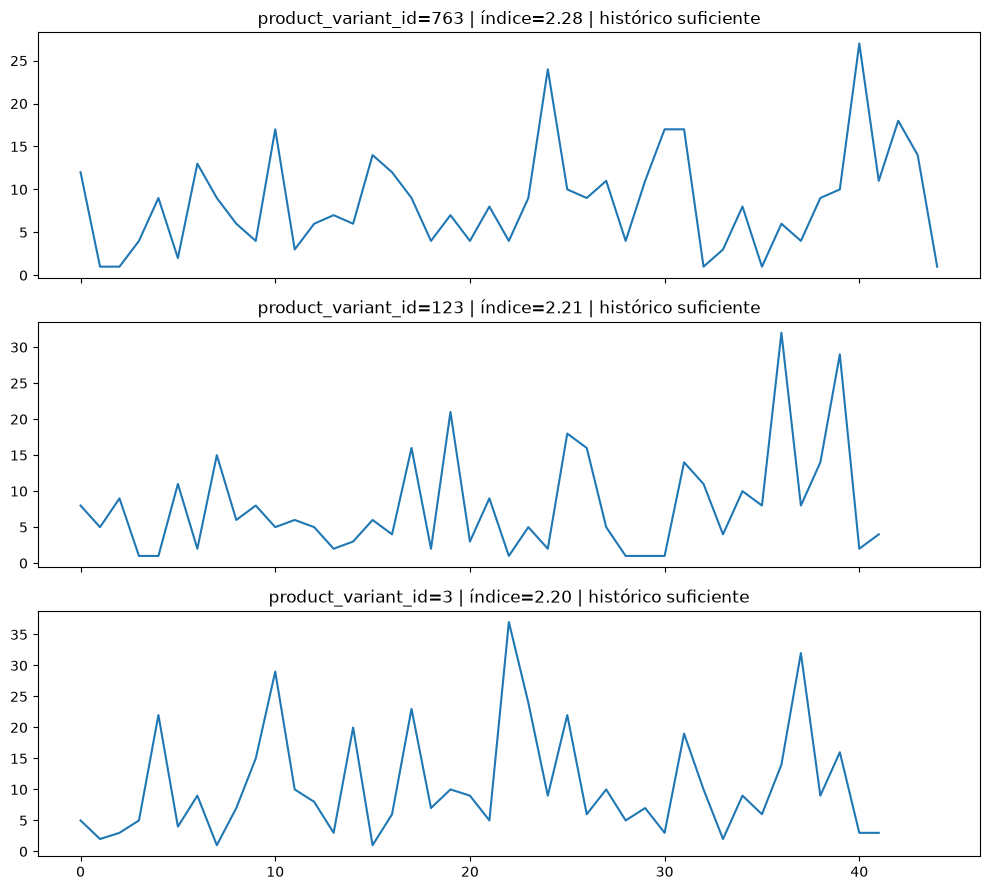

In [ ]:
variantes_maduras = set(df_hist.loc[df_hist['historico_suficiente'], 'product_variant_id'])

df_variant_month = run_query("""
    SELECT product_variant_id, ano, mes, SUM(quantidade_mes) AS quantidade
    FROM eda_base
    GROUP BY product_variant_id, ano, mes
""")
df_variant_month = df_variant_month[df_variant_month.product_variant_id.isin(variantes_maduras)]

MESES_ALTA_TEMPORADA = [12, 1, 2, 3]
df_variant_month['periodo'] = df_variant_month['mes'].apply(
    lambda m: 'alta_temporada' if m in MESES_ALTA_TEMPORADA else 'resto_do_ano'
)

medias = (
    df_variant_month
    .groupby(['product_variant_id', 'periodo'])['quantidade']
    .mean()
    .unstack('periodo')
    .dropna()
)
medias = medias[medias['resto_do_ano'] > 0]
medias['indice_sazonalidade'] = medias['alta_temporada'] / medias['resto_do_ano']

candidatos_finais = medias.sort_values('indice_sazonalidade', ascending=False).head(5)
print(candidatos_finais)

# Confirmação visual das top 3 — evita escolher pelo número isolado
top3 = candidatos_finais.head(3).index.tolist()
fig, axes = plt.subplots(len(top3), 1, figsize=(10, 3*len(top3)), sharex=True)
for ax, variant_id in zip(axes, top3):
    sub = df_variant_month[df_variant_month.product_variant_id == variant_id].sort_values(['ano', 'mes'])
    ax.plot(range(len(sub)), sub['quantidade'])
    ax.set_title(f"product_variant_id={variant_id} | índice={candidatos_finais.loc[variant_id, 'indice_sazonalidade']:.2f} | histórico suficiente")
plt.tight_layout()
plt.show()

### Célula 7 — Encerrar a conexão

In [16]:
connection.close()